# FLO-2D results with pyramids-mesh

**FLO-2D** is a floodplain model on a square-cell grid. pyramids-mesh reads the pair `TIMDEP.HDF5` (time series of FLOW DEPTH, velocity, water-surface elevation) together with `DEPFP.OUT` (per-element maximum floodplain depth), building one `UgridDataset` of square faces. This example is a 240-element flume (4 x 60 cells).

## Setup

In [1]:
from pathlib import Path
import numpy as np
from pyramids.netcdf.ugrid import UgridDataset

# Paths are relative to THIS notebook (docs/examples/), never the repo root.
# read_file takes a pathlib.Path - pass Path objects, never str().
DATA = Path("../../examples/data")
DATA.resolve()
import matplotlib.pyplot as plt

## What is on disk

The driver uses both files together: the HDF5 time series and the OUT summary.

In [2]:
for p in sorted((DATA / "flo2d").iterdir()):
    print(p.name, f"({p.stat().st_size:,} bytes)")

DEPFP.OUT (14,160 bytes)
SOURCE.txt (447 bytes)
TIMDEP.HDF5 (4,183,654 bytes)


## Quickstart read

Pass `driver="flo2d"` and point at the HDF5; the driver picks up the companion `DEPFP.OUT` from the same folder.

In [3]:
ds = UgridDataset.read_file(DATA / "flo2d" / "TIMDEP.HDF5", driver="flo2d")
ds

UgridDataset(mesh='mesh2d', n_node=305, n_face=240, n_edge=0, variables=['max_floodplain_depth', 'FLOW DEPTH', 'Floodplain Water Surface Elevation', 'Velocity MAG'])

In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

`FLOW DEPTH` and `Velocity MAG` are time-varying; `max_floodplain_depth` (from `DEPFP.OUT`) is the per-element peak depth over the run; `Floodplain Water Surface Elevation` is the stage.

## Explore the dataset

A `UgridDataset` wraps a UGRID-style unstructured mesh plus any data variables that ride on it. The scalar properties below describe the grid at a glance: how many nodes and faces it has, its coordinate reference system, and its spatial extent.

The grid is a tall, narrow flume: 4 columns by 60 rows of 50-unit square cells.

In [5]:
print("n_node:", ds.n_node)
print("n_face:", ds.n_face)
print("crs:   ", ds.crs)
print("epsg:  ", ds.epsg)
print("bounds:", ds.bounds)  # (xmin, ymin, xmax, ymax)

n_node: 305
n_face: 240
crs:    None
epsg:   None
bounds: (-25.0, -25.0, 175.0, 2975.0)


`crs`/`epsg` are often `None`: many hydraulic-model result files store coordinates without an embedded CRS, so pyramids reports the geometry faithfully and leaves georeferencing to you. The `bounds` tuple is the mesh envelope in the file's own coordinate units.

### Data variables

`data_variable_names` lists every field attached to the mesh. These are the real model results - water levels, depths, velocities - that make a results file worth reading.

In [6]:
ds.data_variable_names

['max_floodplain_depth',
 'FLOW DEPTH',
 'Floodplain Water Surface Elevation',
 'Velocity MAG']

`summary()` returns a tidy `pandas.DataFrame` of per-variable statistics (count, min, max, mean, std) - a quick sanity check on magnitudes and fill values.

In [7]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
max_floodplain_depth,240,0.0615,0.408400,0.300830,0.085927
FLOW DEPTH,144000,0.0000,7.015525,6.510067,1.243974
Floodplain Water Surface Elevation,144000,0.0000,15.865525,10.951316,2.910526
Velocity MAG,144000,0.0000,7.510303,5.226126,1.224978


## The Mesh2d geometry

`ds.mesh` is a `Mesh2d`: the topology the data variables are defined on. Nodes carry the `(x, y)` coordinates; `face_node_connectivity` says which nodes form each face (a row per face, padded to the maximum vertex count).

In [8]:
mesh = ds.mesh
nx, ny = np.asarray(mesh.node_x), np.asarray(mesh.node_y)
fnc = np.asarray(mesh.face_node_connectivity.data)
print("node_x:", nx.shape, " node_y:", ny.shape)
print("face_node_connectivity:", fnc.shape, " (n_face, max_vertices)")
fnc[:3]

node_x: (305,)  node_y: (305,)
face_node_connectivity: (240, 4)  (n_face, max_vertices)


array([[  0,  61,  62,   1],
       [ 61, 122, 123,  62],
       [122, 183, 184, 123]])

`face_areas` gives the area of every face; `face_centroids` is a `(2, n_face)` array of face centre coordinates. Both are derived straight from the topology.

In [9]:
areas = np.asarray(mesh.face_areas)
cen = np.asarray(mesh.face_centroids)  # shape (2, n_face)
print("face_areas:", areas.shape, " mean area:", round(float(areas.mean()), 4))
print("face_centroids:", cen.shape)

face_areas: (240,)  mean area: 2500.0
face_centroids: (2, 240)


## Wireframe - the bare mesh

`plot_outline()` draws the mesh edges with no data colouring. It is the fastest way to see the grid's shape, resolution, and how faces are distributed before looking at any results.

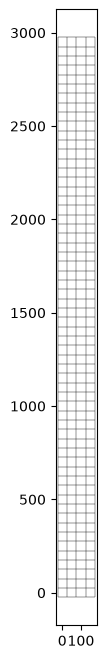

In [10]:
ds.plot_outline()


## Mapping the real results

`FLOW DEPTH` carries a long time axis, so we select the final stored step (the fully developed flood) with `isel`. `max_floodplain_depth` is already a per-element peak and needs no timestep - it maps directly.

In [11]:
STEP = len(ds.time_values) - 1  # last timestep
step = ds.isel(time=STEP)
print("mapping timestep", STEP, "of", len(ds.time_values))

mapping timestep 599 of 600


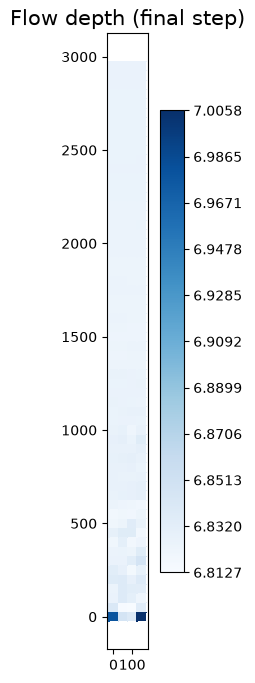

In [12]:
step.plot("FLOW DEPTH", cmap="Blues", colorbar=True, title="Flow depth (final step)")


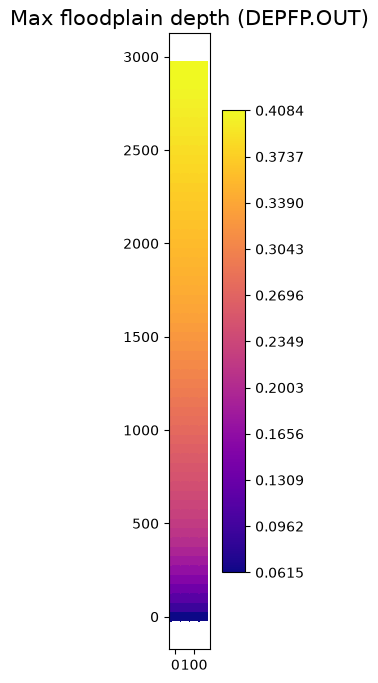

In [13]:
ds.plot("max_floodplain_depth", cmap="plasma", colorbar=True, title="Max floodplain depth (DEPFP.OUT)")


## From mesh to GIS

A `UgridDataset` is not a dead end - it converts into the vector and raster types the rest of a GIS workflow expects. Everything below is reached through pyramids; this package only supplies the file-format driver that built the mesh.

### Faces as vector polygons

`to_geodataframe(variable_name=...)` turns every face into a polygon row carrying that variable's value - a standard GeoPandas `GeoDataFrame` you can join, filter, or export.

In [14]:
gdf = ds.to_geodataframe(variable_name="max_floodplain_depth")
print("rows:", len(gdf), " columns:", list(gdf.columns), " crs:", gdf.crs)
gdf.head()

rows: 240  columns: ['max_floodplain_depth', 'geometry']  crs: None


,max_floodplain_depth,geometry
0,0.0615,"POLYGON ((-25 -25, 25 -25, 25 25, -25 25, -25 ..."
1,0.0615,"POLYGON ((25 -25, 75 -25, 75 25, 25 25, 25 -25))"
2,0.0615,"POLYGON ((75 -25, 125 -25, 125 25, 75 25, 75 -..."
3,0.0615,"POLYGON ((125 -25, 175 -25, 175 25, 125 25, 12..."
4,0.0914,"POLYGON ((-25 25, 25 25, 25 75, -25 75, -25 25))"


Plotting that `GeoDataFrame` straight through GeoPandas (matplotlib under the hood) gives a choropleth of the same values, now as independent vector features.

Text(0.5, 1.0, 'max_floodplain_depth - per-face polygons')

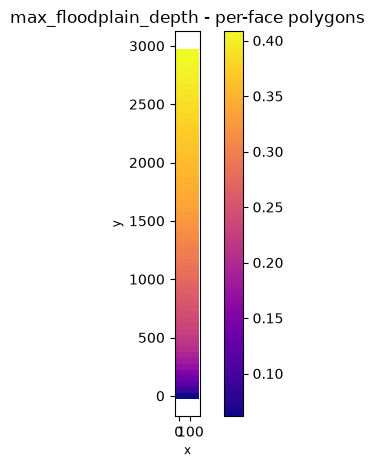

In [15]:
gdf.plot(column="max_floodplain_depth", cmap="plasma", legend=True, figsize=(6, 5))
plt.title("max_floodplain_depth - per-face polygons")


### Dissolving into zones

`polygonize(variable)` merges neighbouring faces that share a value into larger polygons - handy for turning a noisy per-cell field into clean zones. It needs a single value per face, which is exactly what our working dataset holds.

dissolved polygons: 59  columns: ['value', 'geometry']


Text(0.5, 1.0, 'Dissolved value zones')

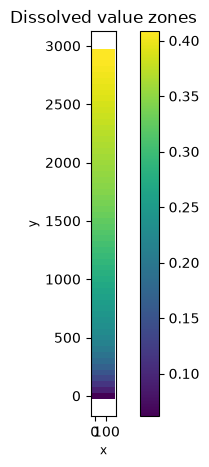

In [16]:
zones = ds.polygonize("max_floodplain_depth")
print("dissolved polygons:", len(zones), " columns:", list(zones.columns))
zones.plot(column="value", cmap="viridis", legend=True, figsize=(6, 5))
plt.title("Dissolved value zones")


### Sampling at points

`sample(variable, x, y)` reads the value of the face that contains each query point. Here we probe the first few face centroids, so each query lands squarely inside a face.

In [17]:
cen = np.asarray(ds.mesh.face_centroids)
xs, ys = cen[0][:5], cen[1][:5]
vals = ds.sample("max_floodplain_depth", xs, ys)
for x, y, v in zip(xs, ys, np.asarray(vals)):
    print(f"({x:10.2f}, {y:10.2f}) -> {float(v):.4f}")

(      0.00,       0.00) -> 0.0615
(     50.00,       0.00) -> 0.0615
(    100.00,       0.00) -> 0.0615
(    150.00,       0.00) -> 0.0615
(      0.00,      50.00) -> 0.0914


### The mesh outline as one polygon

`bounding_polygon()` returns a single shapely polygon tracing the mesh's outer boundary - the model's wetted footprint, useful as a clip mask or extent reference.

Text(0.5, 1.0, 'Mesh bounding polygon')

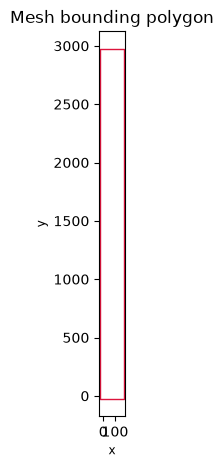

In [18]:
poly = ds.bounding_polygon()
import geopandas as gpd
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="crimson", figsize=(5, 5))
plt.title("Mesh bounding polygon")


### Cropping to a sub-region

`subset_by_bounds(xmin, ymin, xmax, ymax)` returns a new, smaller `UgridDataset` holding only the faces inside the box - the same object type, so every operation above still applies. We derive a box from the mesh envelope so it works on any extent.

faces in full mesh: 240  -> in subset: 60


Text(0.5, 1.0, 'Lower-left quadrant subset')

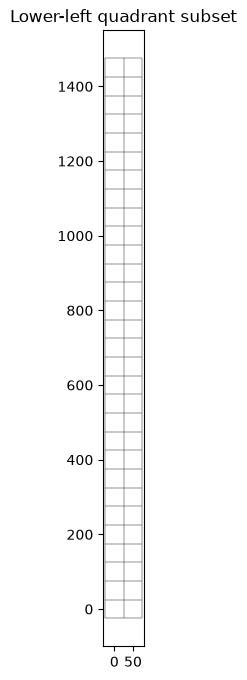

In [19]:
xmin, ymin, xmax, ymax = ds.bounds
mx, my = (xmin + xmax) / 2, (ymin + ymax) / 2
sub = ds.subset_by_bounds(xmin, ymin, mx, my)
print("faces in full mesh:", ds.n_face, " -> in subset:", sub.n_face)
sub.plot_outline()
plt.title("Lower-left quadrant subset")


### Connectivity as a sparse graph

`sparse_adjacency()` exposes face-to-face adjacency as a SciPy sparse matrix, and `connected_components()` labels each face by which connected piece of the mesh it belongs to - the entry points for graph algorithms over the grid.

In [20]:
adj = ds.sparse_adjacency()
print("adjacency:", adj.shape, " non-zeros:", adj.nnz)
labels = ds.connected_components()
print("connected components:", len(np.unique(np.asarray(labels))))

adjacency: (240, 240)  non-zeros: 832
connected components: 1


### Circumcenters - not applicable here

`circumcenters()` is only defined for purely triangular meshes. This grid contains quad (or mixed-polygon) faces, so the call would raise `ValueError`. We note it and skip rather than force it.

### Self-contained rasterisation

`to_dataset(variable, cell_size=...)` samples the mesh onto a regular raster grid and returns a pyramids `Dataset`. Unlike `rasterize_like` / `regrid` - which need an existing reference grid and are therefore skipped here - this is self-contained: you only choose a cell size.

rasterised to: Dataset


Text(0.5, 1.0, 'max_floodplain_depth rasterised')

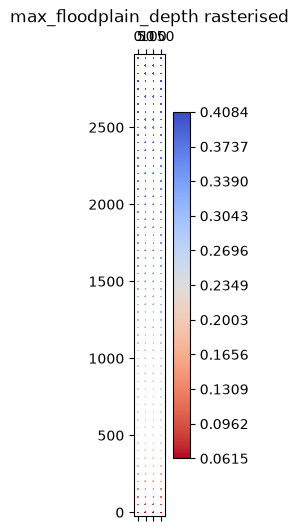

In [21]:
step_xy = (ds.bounds[2] - ds.bounds[0]) / 60
rast = ds.to_dataset("max_floodplain_depth", cell_size=step_xy)
print("rasterised to:", type(rast).__name__)
rast.plot()
plt.title("max_floodplain_depth rasterised")


### Reprojection - skipped

`to_crs(...)` needs a *source* CRS to project from. FLO-2D stores grid coordinates without a CRS, so `ds.crs` is `None`. With no source CRS, reprojection is undefined, so we skip it; assign a CRS first if your coordinates are georeferenced.

### Back to xarray

`to_xarray()` hands the whole dataset back as an `xarray.Dataset`, so you can drop into the full xarray ecosystem (time selection, resampling, NetCDF export) whenever you need it.

In [22]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.data_vars)[:6]

('Dataset',
 ['mesh2d',
  'mesh2d_node_x',
  'mesh2d_node_y',
  'mesh2d_face_nodes',
  'mesh2d_face_x',
  'mesh2d_face_y'])

## Takeaway

FLO-2D shows a driver stitching **two** files into one mesh: the HDF5 time series and the OUT summary land on the same square-cell grid. Select the last timestep for the evolving `FLOW DEPTH`, map the static `max_floodplain_depth` directly, then reuse the vector and raster conversions. File assembly is the driver's job; the mesh operations are pyramids'.